# 10 · Проверка зафиксированной модели на другой дате

**Вопрос:** сохраняется ли улучшение при переходе с 21 на 28 октября 2019 года?

До просмотра ошибок выбраны первые 10 хронологических рейсов EGCC/EPWA с C40 после 22:05 и посадкой до 22:58 UTC. Это позволяет использовать один публичный час. Пропавшие рейсы не заменяем другими. Модель 08, ее коэффициенты, стандартизация и список признаков зафиксированы. **Обучения и настройки на новых данных нет**.

Новая дата не была частью 07–09. Но аэропорты и сезон близки к обучению, а наблюдения поступают из того же источника. Это проверка на другом дне, не доказательство универсальной переносимости. Проверочный ответ – скрытое наблюдение OpenSky.

In [1]:
# Загружаем протокол, происхождение новых данных и замороженную модель
from pathlib import Path
import contextlib
import io
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
sys.path.insert(0,str(study/'scripts'))
from evaluate_hidden_points import main as evaluate_baselines
from audit_c40_radial_cases import ellipsoid_distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
protocol = json.loads((study/'reports/10_external_protocol.json').read_text(encoding='utf8'))
download = json.loads((study/'reports/10_external_download.json').read_text(encoding='utf8'))
model_path = study/'data/public_pilot/08_ridge_model.npz'
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == protocol['model_sha256']
model = np.load(model_path,allow_pickle=False)
source_path = study/'data/external_day/external_geometry.csv'
assert hashlib.sha256(source_path.read_bytes()).hexdigest() == download['selected_sha256']
source = pd.read_csv(source_path)
assert pd.to_datetime(source.time,unit='s',utc=True).dt.strftime('%Y-%m-%d').eq(protocol['day']).all()
original_split = json.loads((study/'reports/08_ml_protocol.json').read_text(encoding='utf8'))['split']
assert not set(source.case_flight_id).intersection(original_split)
display(pd.DataFrame(download['flights']))
display(Markdown(f"**Дата:** {protocol['day']} · **Источник:** {download['url']} · **Модель:** α={float(model['alpha']):g}"))
# Повторяем неизменные правила скрытия точек и сохраняем отдельные результаты
with contextlib.redirect_stdout(io.StringIO()):
    evaluate_baselines(source_path,prefix='10_external')
baseline_errors = pd.read_csv(source_path.parent/'10_external_hidden_point_errors.csv')
split = {f:'external' for f in source.case_flight_id.unique()}

,flight_id,rows,expected_callsign,callsigns,callsign_present
0,RYR5LT_64706,128,RYR5LT,[RYR5LT],True
1,SAS2761_9489,129,SAS2761,[SAS2761],True
2,EZY16KQ_14918,117,EZY16KQ,[EZY16KQ],True
3,RYR2WF_61517,129,RYR2WF,[RYR2WF],True
4,EZY61VB_24426,138,EZY61VB,[EZY61VB],True
5,BEL2UQ_43904,138,BEL2UQ,[BEL2UQ],True
6,PGT7211_51297,144,PGT7211,[PGT7211],True
7,DLH948_5597,142,DLH948,[DLH948],True
8,EXS4TQ_30203,168,EXS4TQ,[EXS4TQ],True
9,WZZ100D_15479,126,WZZ100D,[WZZ100D],True


**Дата:** 2019-10-28 · **Источник:** https://s3.opensky-network.org/data-samples/states/.2019-10-28/22/states_2019-10-28-22.csv.tar · **Модель:** α=100

## 1. Формируем те же признаки по доступным концам

Код ниже совпадает с формированием признаков 08. Скрытые координаты входят только в проверочную поправку. При отсутствии необходимых признаков сохраняем учет пропусков и сравниваем методы на общих целях.

In [2]:
# Берем точно те же цели, которые сравнивались в эксперименте 07
key = ['flight_id','gap_s','left_time','target_time']
tasks = baseline_errors[baseline_errors.method.eq('linear_lat_lon')][key].copy()
assert not tasks.duplicated(key).any()
observed = source.rename(columns={'case_flight_id':'flight_id'})
assert not observed.duplicated(['flight_id','time']).any()
tasks['right_time'] = tasks.left_time+tasks.gap_s
# Присоединяем доступные концы отдельно от скрытого ответа
for role,time_col in [('a','left_time'),('b','right_time'),('target','target_time')]:
    fields = ['flight_id','time','lat','lon']
    if role != 'target':
        fields += ['velocity','heading','lastposupdate']
    renamed = observed[fields].rename(columns={c:f'{role}_{c}' for c in fields if c != 'flight_id'})
    tasks = tasks.merge(renamed,left_on=['flight_id',time_col],right_on=['flight_id',f'{role}_time'],validate='many_to_one')
tasks['part'] = tasks.flight_id.map(split)
w = (tasks.target_time-tasks.left_time)/tasks.gap_s
duration = tasks.gap_s
# Линейная интерполяция определяется только доступными концами
lon_delta = (tasks.b_lon-tasks.a_lon+180)%360-180
linear_lat = tasks.a_lat+w*(tasks.b_lat-tasks.a_lat)
linear_lon = tasks.a_lon+w*lon_delta
east_scale = 111320*np.cos(np.radians((tasks.a_lat+tasks.b_lat)/2))
north_scale = 111200
east = lon_delta*east_scale
north = (tasks.b_lat-tasks.a_lat)*north_scale
ha,hb = np.radians(tasks.a_heading),np.radians(tasks.b_heading)
va_e,va_n = tasks.a_velocity*np.sin(ha),tasks.a_velocity*np.cos(ha)
vb_e,vb_n = tasks.b_velocity*np.sin(hb),tasks.b_velocity*np.cos(hb)
curve = w*(1-w)*duration
# Кинематические подсказки используют только скорость и направление концов
features = pd.DataFrame({'gap_s':duration,'fraction':w,'curve_time_s':curve,
    'speed_a':tasks.a_velocity,'speed_b':tasks.b_velocity,
    'heading_a_sin':np.sin(ha),'heading_a_cos':np.cos(ha),
    'heading_b_sin':np.sin(hb),'heading_b_cos':np.cos(hb),
    'age_a':tasks.a_time-tasks.a_lastposupdate,'age_b':tasks.b_time-tasks.b_lastposupdate,
    'east_span':east,'north_span':north,
    'forward_residual_e':va_e*w*duration-w*east,
    'forward_residual_n':va_n*w*duration-w*north,
    'backward_residual_e':(1-w)*east-vb_e*(1-w)*duration,
    'backward_residual_n':(1-w)*north-vb_n*(1-w)*duration,
    'velocity_change_e':(vb_e-va_e)*curve,'velocity_change_n':(vb_n-va_n)*curve})
# Координаты скрытых точек появляются только в целевой поправке
target = np.column_stack([((tasks.target_lon-linear_lon+180)%360-180)*east_scale,
                          (tasks.target_lat-linear_lat)*north_scale])
usable = np.isfinite(features).all(axis=1) & np.isfinite(target).all(axis=1)
display(tasks.assign(usable=usable).groupby('part').agg(total=('flight_id','size'),usable=('usable','sum')))
# Сравниваем все методы на общей подвыборке при наличии пропусков признаков
tasks = tasks.loc[usable].reset_index(drop=True)
features = features.loc[usable].reset_index(drop=True)
target = target[usable]
linear_lat = linear_lat.loc[usable].to_numpy()
linear_lon = linear_lon.loc[usable].to_numpy()
east_scale = east_scale.loc[usable].to_numpy()
assert set(tasks.flight_id) == set(split)
display(features.head().round(3))
display(tasks.groupby(['part','flight_id']).size().rename('Число задач'))

,total,usable
part,,
external,21727,21727


,gap_s,fraction,curve_time_s,speed_a,speed_b,heading_a_sin,heading_a_cos,heading_b_sin,heading_b_cos,age_a,age_b,east_span,north_span,forward_residual_e,forward_residual_n,backward_residual_e,backward_residual_n,velocity_change_e,velocity_change_n
0,20,0.5,5.0,190.584,190.200,-0.664,0.748,-0.665,0.747,1.523,0.688,-2626.988,2950.667,47.962,-50.324,-47.962,55.468,0.000,-2.572
1,20,0.5,5.0,189.473,192.379,-0.665,0.747,-0.666,0.746,0.468,0.895,-2431.264,2730.661,-44.756,49.390,65.333,-69.968,-10.289,10.289
2,20,0.5,5.0,190.200,193.489,-0.665,0.747,-0.665,0.747,0.688,0.135,-2619.204,2942.212,44.070,-51.241,-23.492,25.518,-10.289,12.861
3,20,0.5,5.0,192.379,192.763,-0.666,0.746,-0.665,0.747,0.895,0.026,-2707.877,3041.258,72.973,-85.330,-72.973,80.186,0.000,2.572
4,20,0.5,5.0,193.489,191.310,-0.665,0.747,-0.664,0.748,0.135,0.158,-2556.120,2876.038,-8.050,7.569,-7.383,7.864,7.717,-7.717


part      flight_id    
external  BEL2UQ_43904     2186
          DLH948_5597      2338
          EXS4TQ_30203     2775
          EZY16KQ_14918    1863
          EZY61VB_24426    2243
          PGT7211_51297    2300
          RYR2WF_61517     1977
          RYR5LT_64706     1996
          SAS2761_9489     2053
          WZZ100D_15479    1996
Name: Число задач, dtype: int64

## 2. Применяем сохраненные коэффициенты

Среднее и масштаб признаков загружаем из модели 08, а не пересчитываем по новой дате. Проверяем порядок признаков и точное воспроизведение линейного ориентира. Уменьшение ошибки не гарантировано.

In [3]:
# Проверяем схему признаков перед применением модели
assert list(features.columns) == model['feature_names'].tolist()
x = np.column_stack([np.ones(len(features)),(features.to_numpy()-model['mean'])/model['scale']])
correction = x@model['coef']
pred_lat = linear_lat+correction[:,1]/north_scale
pred_lon = linear_lon+correction[:,0]/east_scale
model_errors = 1000*ellipsoid_distance(tasks.target_lat.to_numpy(),tasks.target_lon.to_numpy(),pred_lat,pred_lon)
assert np.isfinite(model_errors).all()
evaluation = baseline_errors.merge(tasks[key],on=key,how='inner',validate='many_to_one')
ml = tasks[key].copy()
ml['method'] = 'ridge_correction'
ml['error_m'] = model_errors
evaluation = pd.concat([evaluation,ml],ignore_index=True)
assert evaluation.groupby(key).method.nunique().eq(4).all()
linear_error = 1000*ellipsoid_distance(tasks.target_lat.to_numpy(),tasks.target_lon.to_numpy(),linear_lat,linear_lon)
saved_linear = evaluation[evaluation.method.eq('linear_lat_lon')].set_index(key).error_m
assert np.allclose(saved_linear.reindex(pd.MultiIndex.from_frame(tasks[key])),linear_error,atol=1e-5)
# Ошибки агрегируем по рейсам, чтобы количество окон не определяло их вес
summary = evaluation.groupby(['flight_id','method']).error_m.agg(
    targets='size',mean_m='mean',median_m='median',p95_m=lambda s:s.quantile(.95),max_m='max').reset_index()
macro = summary.groupby('method')[['mean_m','median_m','p95_m']].mean()
display(macro.round(2))
display(summary.round(2))
# Проверяем, что коэффициенты не были перезаписаны
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == protocol['model_sha256']

,mean_m,median_m,p95_m
method,,,
constant_velocity_sphere,782.09,142.76,4189.99
linear_lat_lon,420.47,137.93,2002.99
nearest,3558.86,2856.60,8792.84
ridge_correction,173.22,82.14,704.38


,flight_id,method,targets,mean_m,median_m,p95_m,max_m
0,BEL2UQ_43904,constant_velocity_sphere,2186,786.08,141.73,4167.83,14803.87
1,BEL2UQ_43904,linear_lat_lon,2186,418.88,135.85,2091.27,4183.50
2,BEL2UQ_43904,nearest,2186,3462.96,2644.68,8922.73,11753.05
3,BEL2UQ_43904,ridge_correction,2186,184.86,89.90,803.15,1623.86
4,DLH948_5597,constant_velocity_sphere,2338,763.18,139.32,3775.72,12643.25
5,DLH948_5597,linear_lat_lon,2338,392.81,133.93,1906.87,3574.78
6,DLH948_5597,nearest,2338,3052.79,2585.88,7518.22,10066.17
7,DLH948_5597,ridge_correction,2338,164.36,77.24,630.60,1490.15
8,EXS4TQ_30203,constant_velocity_sphere,2775,572.05,138.02,3435.70,11033.48
9,EXS4TQ_30203,linear_lat_lon,2775,326.77,124.00,1488.92,3170.73


## 3. Сравниваем рейсы, пропуски и ухудшения

Зеленый – линейная интерполяция, красный – зафиксированная модель. Среднее рейсовых P95 не является P95 объединенной выборки. Доля ухудшений считается по парным целям, а не по разным подвыборкам.

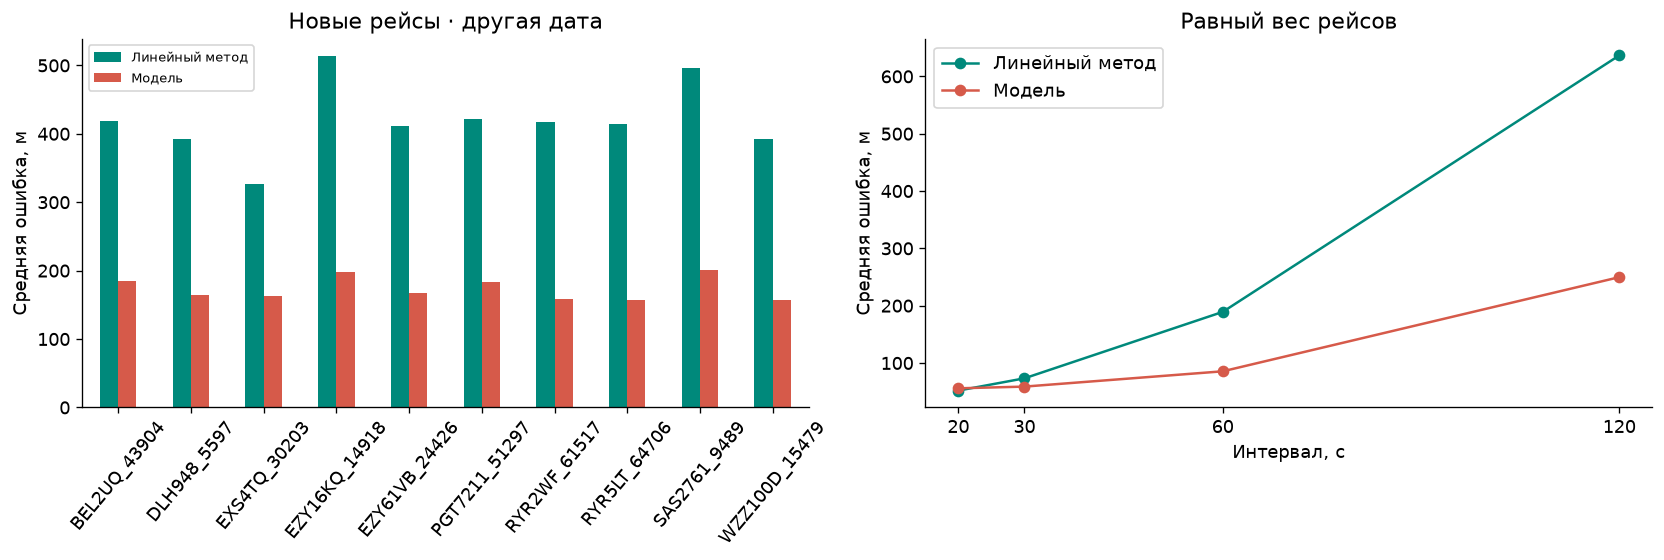

flight_id
BEL2UQ_43904     0.346
DLH948_5597      0.337
EXS4TQ_30203     0.401
EZY16KQ_14918    0.297
EZY61VB_24426    0.325
PGT7211_51297    0.337
RYR2WF_61517     0.334
RYR5LT_64706     0.333
SAS2761_9489     0.281
WZZ100D_15479    0.311
Name: Доля ухудшений, dtype: float64

**Новая дата:** средняя рейсовая ошибка 420.5 → 173.2 м; изменение в пользу модели +58.8%. Улучшение среднего на 10 из 10 рейсов.

897

In [4]:
colors = {'linear_lat_lon':'#00897B','ridge_correction':'#D65A4A'}
labels = {'linear_lat_lon':'Линейный метод','ridge_correction':'Модель'}
fig, axes = plt.subplots(1,2,figsize=(14,4.8))
table = summary[summary.method.isin(labels)].pivot(index='flight_id',columns='method',values='mean_m')
table.rename(columns=labels).plot.bar(ax=axes[0],color=[colors[m] for m in table.columns])
axes[0].set(xlabel='',ylabel='Средняя ошибка, м',title='Новые рейсы · другая дата')
axes[0].tick_params(axis='x',rotation=50)
axes[0].legend(fontsize=8)
by_gap = evaluation.groupby(['flight_id','gap_s','method']).error_m.mean().reset_index()
gap = by_gap.groupby(['gap_s','method']).error_m.mean().reset_index()
for method in labels:
    group = gap[gap.method.eq(method)]
    axes[1].plot(group.gap_s,group.error_m,'o-',color=colors[method],label=labels[method])
axes[1].set(xlabel='Интервал, с',ylabel='Средняя ошибка, м',title='Равный вес рейсов',xticks=[20,30,60,120])
axes[1].legend()
plt.tight_layout()
fig.savefig(study/'figures/10_external_validation.png',dpi=180)
plt.show()
# Считаем долю целей с ухудшением отдельно для каждого нового рейса
paired = evaluation.pivot(index=key,columns='method',values='error_m').reset_index()
paired['worse'] = paired.ridge_correction > paired.linear_lat_lon
display(paired.groupby('flight_id').worse.mean().rename('Доля ухудшений').round(3))
baseline = float(macro.loc['linear_lat_lon','mean_m'])
learned = float(macro.loc['ridge_correction','mean_m'])
improvement = 100*(baseline-learned)/baseline
wins = int((table.ridge_correction < table.linear_lat_lon).sum())
display(Markdown(f'**Новая дата:** средняя рейсовая ошибка {baseline:.1f} → {learned:.1f} м; '
                 f'изменение в пользу модели {improvement:+.1f}%. Улучшение среднего на {wins} из {len(table)} рейсов.'))
summary.to_csv(study/'reports/10_external_by_flight.csv',index=False)
macro.to_csv(study/'reports/10_external_macro.csv')
gap.to_csv(study/'reports/10_external_by_gap.csv',index=False)
evaluation.to_csv(source_path.parent/'10_external_ml_errors.csv',index=False)
result = {'day':protocol['day'],'selected_flights':len(protocol['cases']),'evaluated_flights':len(table),
    'tasks':len(tasks),'linear_macro_mean_m':baseline,'model_macro_mean_m':learned,
    'improvement_percent':improvement,'flights_improved':wins,
    'model_sha256':protocol['model_sha256'],'source_sha256':download['selected_sha256'],
    'model_refit':False,'fraction_worse_by_flight':paired.groupby('flight_id').worse.mean().to_dict()}
(study/'reports/10_external_audit.json').write_text(json.dumps(result,ensure_ascii=False,indent=2)+'\n',encoding='utf8')

## Границы результата

Результат относится к выбранному часу другой даты и найденным рейсам. Их выбор зафиксирован до оценки модели. Коэффициенты и параметры преобразований сохранены из 08 без обучения на новых данных.

Перекрывающиеся окна создают зависимые ошибки. Тот же борт может встречаться в разных датах, поэтому это разделение по полетам и дате, не по самолетам. Близкие аэропорты, сезон и источник ограничивают переносимость. Дальнейшее изменение метода потребует нового независимого набора.

Сырые архивы, траектории и подробные ошибки остаются локально. Источник – публичный архив OpenSky; его URL, размер и SHA256 сохранены в реестре загрузки.